<a href="https://colab.research.google.com/github/mailtotapasishah-cloud/Ml_LAB_2026-27/blob/main/Crop_Recommendation_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Crop Recommendation Using Machine Learning

**Aim:** To recommend a suitable crop using soil nutrients and weather conditions.

This beginner-friendly project uses one CSV dataset and compares five classification algorithms. The dataset is **synthetic educational sample data**, created for learning; it is not agricultural advice or real farm measurements.


## 1. Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


## 2. Load the dataset
Upload `crop_recommendation_dataset.csv` to the Colab Files panel before running this cell.

In [2]:
data = pd.read_csv('crop_recommendation_dataset.csv')
print(data.head())
print("\\nDataset shape:", data.shape)
print("\\nMissing values:\\n", data.isnull().sum())


           N          P          K  temperature   humidity        ph  \
0  82.742454  41.680127  45.253158    27.069242  64.391718  5.614019   
1  77.153817  49.865591  34.028693    26.934676  86.222335  6.229714   
2  84.207584  43.125660  42.581255    22.890458  87.027602  6.177533   
3  73.871634  59.780331  38.918294    24.057679  77.182932  6.439539   
4  83.714594  53.446568  54.991533    24.105887  75.902058  5.833802   

    rainfall  crop  
0  26.022723  rice  
1  34.017930  rice  
2  23.521101  rice  
3  27.923553  rice  
4  29.927835  rice  
\nDataset shape: (1000, 8)
\nMissing values:\n N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
crop           0
dtype: int64


## 3. Separate input and output

In [3]:
X = data.drop('crop', axis=1)
y = data['crop']

print("Input features:", list(X.columns))
print("Crop classes:", sorted(y.unique()))


Input features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Crop classes: ['banana', 'chickpea', 'cotton', 'maize', 'millet', 'rice', 'sugarcane', 'wheat']


## 4. Split the dataset

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


## 5. Apply machine learning algorithms

In [5]:
models = {
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC())
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    score = accuracy_score(y_test, predictions)
    results[name] = score
    print(name, "Accuracy:", round(score * 100, 2), "%")


KNN Accuracy: 89.0 %
Decision Tree Accuracy: 83.5 %
Logistic Regression Accuracy: 93.5 %
Random Forest Accuracy: 92.0 %
SVM Accuracy: 93.5 %


## 6. Compare model accuracy

             Algorithm  Accuracy
2  Logistic Regression     0.935
4                  SVM     0.935
3        Random Forest     0.920
0                  KNN     0.890
1        Decision Tree     0.835


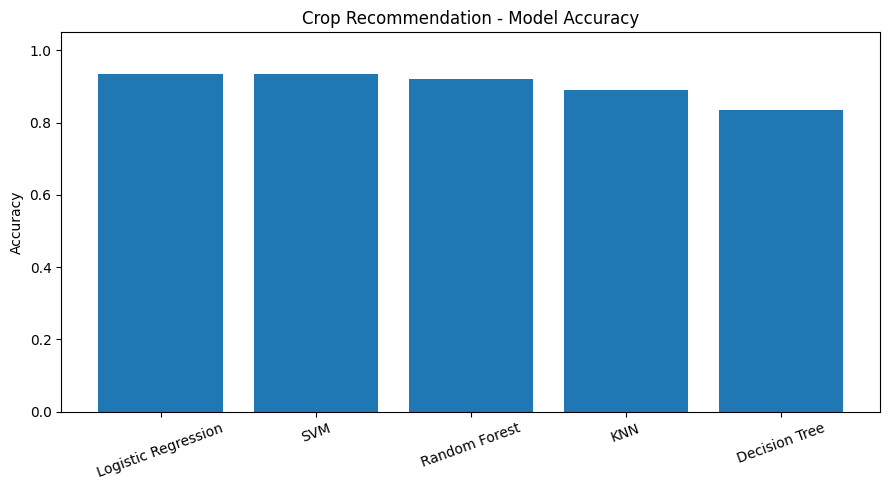

In [6]:
results_df = pd.DataFrame({
    "Algorithm": list(results.keys()),
    "Accuracy": list(results.values())
}).sort_values("Accuracy", ascending=False)

print(results_df)
plt.figure(figsize=(9, 5))
plt.bar(results_df["Algorithm"], results_df["Accuracy"])
plt.ylabel("Accuracy")
plt.title("Crop Recommendation - Model Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 7. Classification report for the best model

In [7]:
best_name = max(results, key=results.get)
best_model = models[best_name]
print("Best model:", best_name)
print(classification_report(y_test, best_model.predict(X_test)))


Best model: Logistic Regression
              precision    recall  f1-score   support

      banana       1.00      0.96      0.98        25
    chickpea       1.00      0.96      0.98        25
      cotton       1.00      1.00      1.00        25
       maize       0.89      1.00      0.94        25
      millet       1.00      1.00      1.00        25
        rice       0.81      0.88      0.85        25
   sugarcane       0.85      0.92      0.88        25
       wheat       0.95      0.76      0.84        25

    accuracy                           0.94       200
   macro avg       0.94      0.94      0.93       200
weighted avg       0.94      0.94      0.93       200



## 8. Predict a crop for new sample conditions
Change the sample values to test another example. Values are illustrative only.

In [8]:
new_sample = pd.DataFrame([{
    "N": 90,
    "P": 45,
    "K": 40,
    "temperature": 25,
    "humidity": 78,
    "ph": 6.3,
    "rainfall": 190
}])

predicted_crop = best_model.predict(new_sample)[0]
print("Recommended crop by the model:", predicted_crop)


Recommended crop by the model: sugarcane


## 9. Conclusion

In this project, one dataset was used to train and compare KNN, Decision Tree, Logistic Regression, Random Forest, and SVM. The model predicts a crop label from the given input features. The best-performing model is selected based on test accuracy.

**Note:** The dataset is synthetic and the prediction is only a classroom demonstration. Real crop selection should consider local soil tests, season, irrigation, region, and advice from agricultural experts.
